   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 3.7 MB/s eta 0:00:00
=== T_LOG QUANTUM v16.0 | MODE = FAST ===
  Realisations : 1 | Steps : 4000 | Test : cohen_d | Algo : metropolis

Points Gamma : 26 | Gamma_c = 3.0440

>>> L = 24

[Build L=24] 1 réalisation(s), 4000 steps, mode fast


L=24 ensemble: 100%|██████████| 1/1 [01:37<00:00, 97.57s/it]


Features : 30
   Gamma  Mz_Higuchi    Mz_DFA   Mz_Katz  Mz_CorrDim
0    2.0    2.047755  1.959497  7.276618    2.172772
1    2.1    2.050984  1.962264  7.020835    2.183452
2    2.2    2.047568  1.956263  5.964996    2.129222


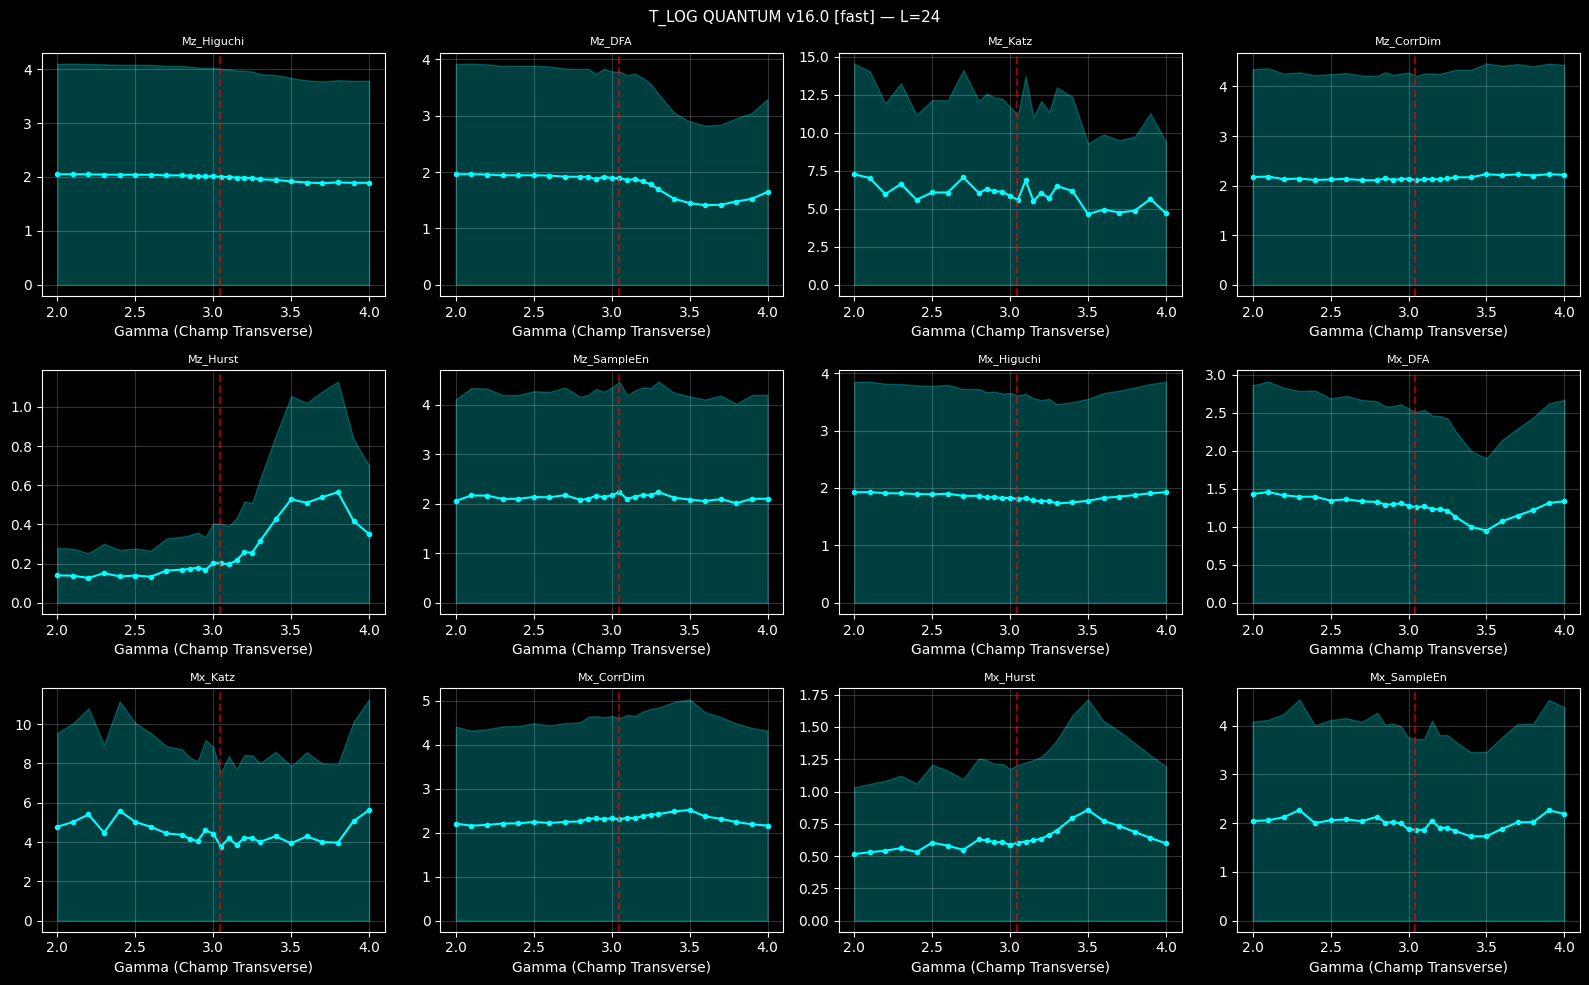


=== 4 Questions (Quantiques) ===
Q1: Ordre vs Desordre...
Q2: Tension critique...
Q3: Apathie vs Dynamisme...
Q4: Symetrie spontanee...

>>> RESULTATS L=24:
                  Q1_Ordre_vs_Desordre  Q2_Tension_critique  Q3_Apathie_vs_Dynamisme  Q4_Symetrie_spontanee
Chi_CorrDim                      2.937                3.355                    2.937                  0.073
Chi_DFA                          3.133                2.818                    3.133                  0.073
Chi_Higuchi                      2.997                2.824                    2.997                  0.073
Chi_Hurst                        2.983                1.465                    2.983                  0.073
Chi_Katz                         3.115                1.090                    3.115                  0.073
Chi_SampleEn                     2.334                3.228                    2.334                  0.073
E_CorrDim                        0.017                2.022                      NaN  

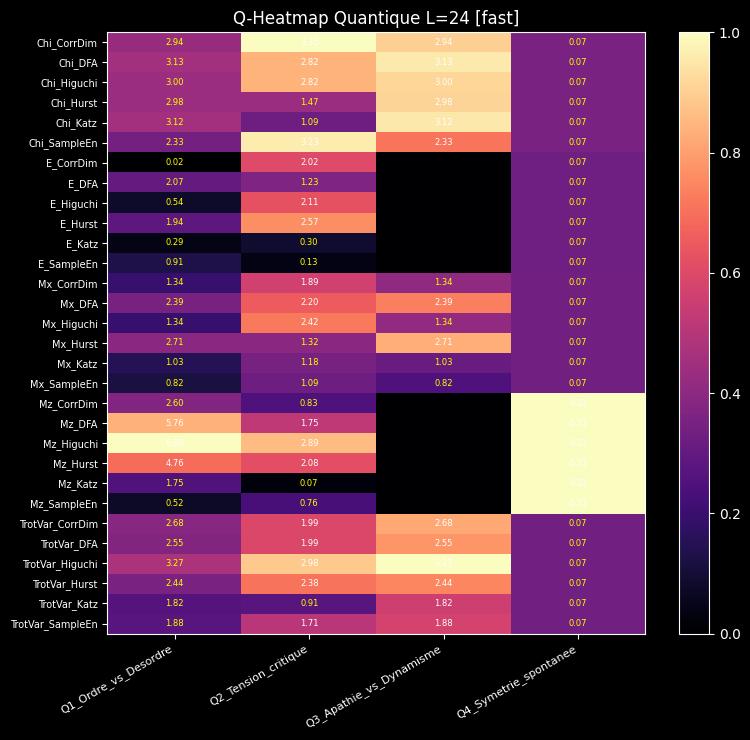


>>> L = 32

[Build L=32] 1 réalisation(s), 4000 steps, mode fast


L=32 ensemble: 100%|██████████| 1/1 [02:09<00:00, 129.28s/it]


Features : 30
   Gamma  Mz_Higuchi    Mz_DFA   Mz_Katz  Mz_CorrDim
0    2.0    2.048354  1.957345  5.303568    2.161536
1    2.1    2.053477  1.951889  6.195544    2.159401
2    2.2    2.006830  1.521175  5.202893    2.178606


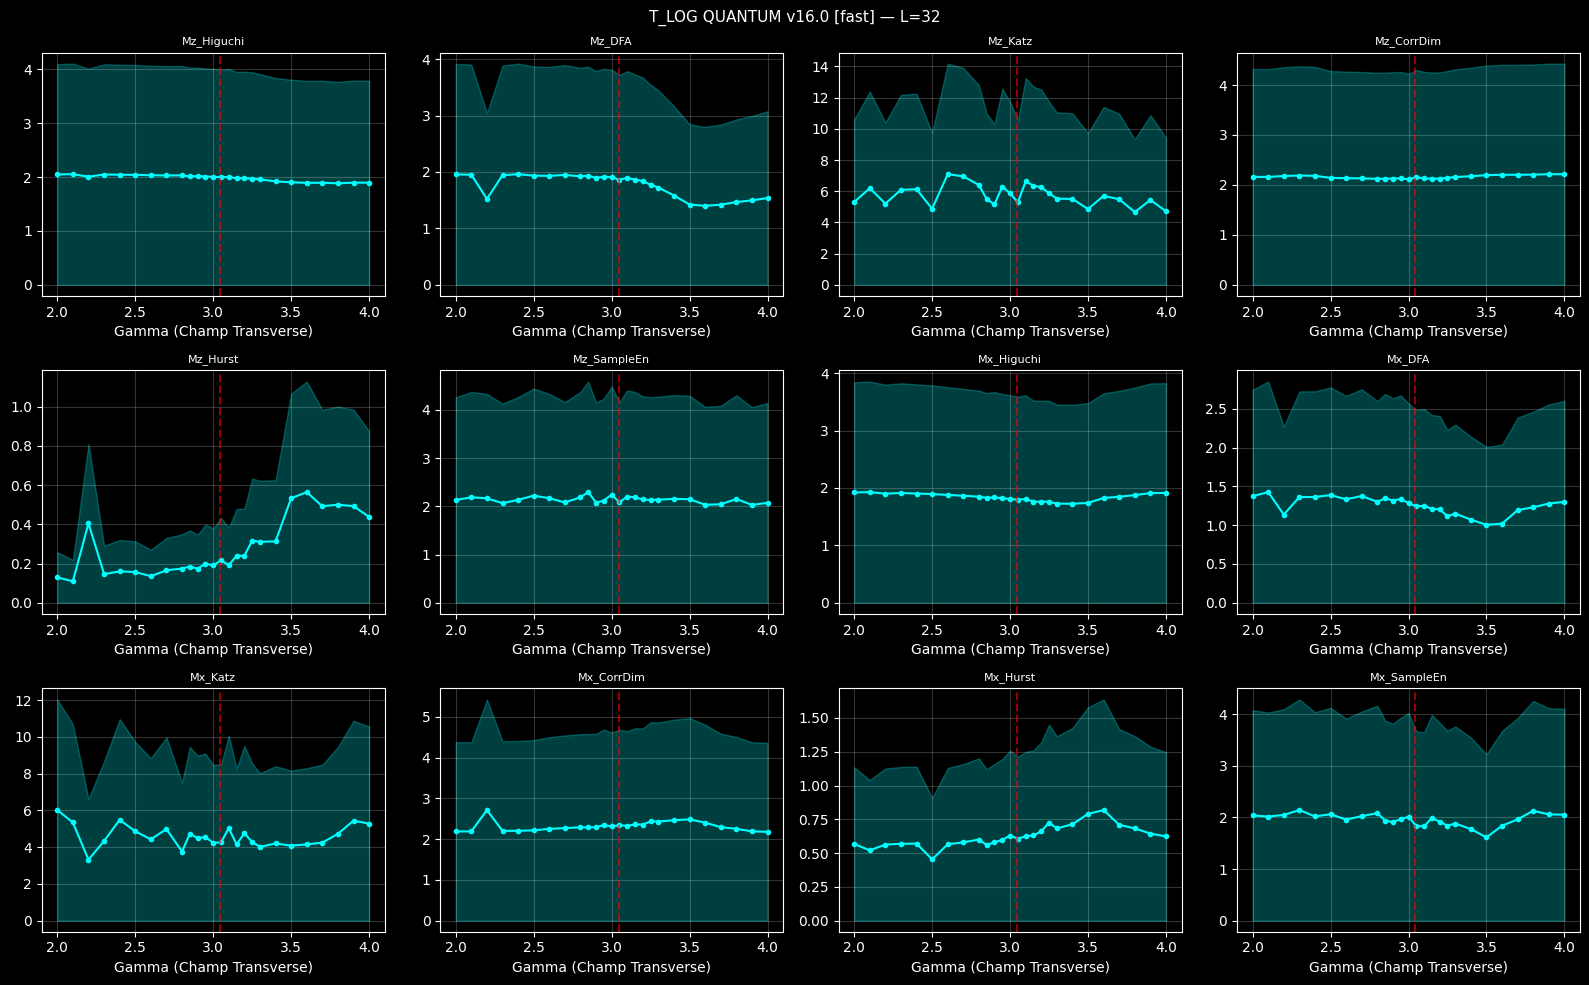


=== 4 Questions (Quantiques) ===
Q1: Ordre vs Desordre...
Q2: Tension critique...
Q3: Apathie vs Dynamisme...
Q4: Symetrie spontanee...

>>> RESULTATS L=32:
                  Q1_Ordre_vs_Desordre  Q2_Tension_critique  Q3_Apathie_vs_Dynamisme  Q4_Symetrie_spontanee
Chi_CorrDim                      1.435                2.972                    1.435                  0.173
Chi_DFA                          2.207                3.150                    2.207                  0.173
Chi_Higuchi                      3.098                3.030                    3.098                  0.173
Chi_Hurst                        3.566                1.750                    3.566                  0.173
Chi_Katz                         1.250                0.049                    1.250                  0.173
Chi_SampleEn                     2.319                2.847                    2.319                  0.173
E_CorrDim                        0.032                0.444                      NaN  

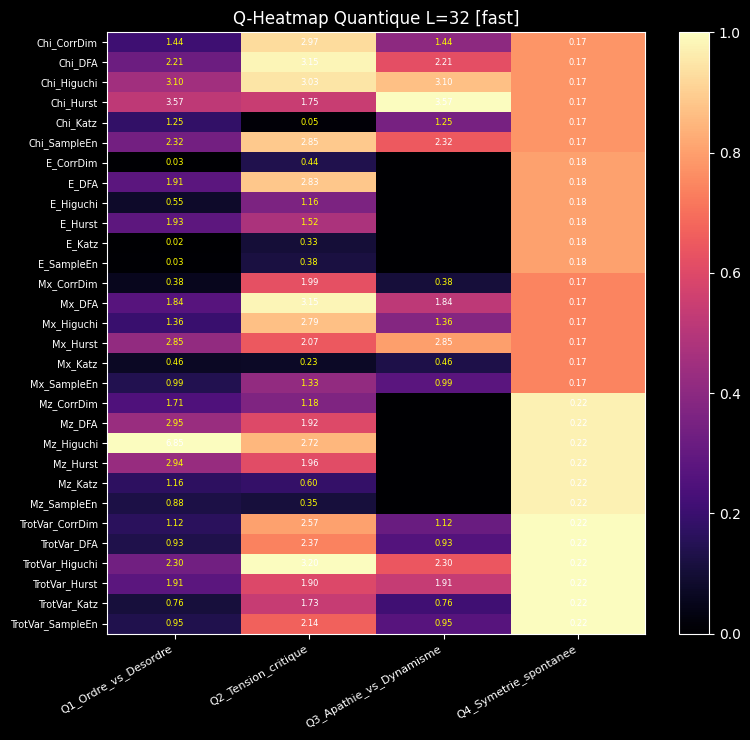


[OK] T_LOG Quantique v16.0 terminé.


In [1]:
# =============================================================================
# T_LOG v16.0 — QUANTUM 2D ISING (Path Integral Monte Carlo 3D)
# =============================================================================
# Mode FAST   : Cohen's d, 1 réalisation, Metropolis, seuils permissifs
# Mode ROBUST : Cliff + Mann-Whitney, Wolff + ensemble, bootstrap
# Basculez avec : MODE = 'fast'  ou  MODE = 'robust'
# =============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import label
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')
# Paramètre critique pour le modèle Quantique Transverse 2D (Gamma_c au lieu de T_c)
GC_EXACT = 3.044

# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION GLOBALE — CHOIX DU MODE
# ═══════════════════════════════════════════════════════════════════════════════
MODE = 'fast'       # <-- 'fast' ou 'robust'

CONFIG = {
    'fast': {
        'n_realizations': 1,
        'steps': 4000,                  # Réduit car la grille est 3D (L*L*L_tau)
        'transient_factor': 0.25,
        'algorithm': 'metropolis',      # toujours Metropolis
        'stat_test': 'cohen_d',         # Cohen's d simple
        'min_per_group': 2,             # seuil très bas pour eviter NaN
        'estimator_min_len': 50,
        'cluster_interval': 50,
        'mann_whitney': False,
        'bootstrap': False,
    },
    'robust': {
        'n_realizations': 5,
        'steps': 15000,
        'transient_factor': 0.25,
        'algorithm': 'auto',            # Wolff près de Gc, Metropolis ailleurs
        'stat_test': 'cliff_delta',     # Cliff's Delta + Mann-Whitney
        'min_per_group': 3,
        'estimator_min_len': 100,
        'cluster_interval': 50,
        'mann_whitney': True,
        'bootstrap': True,
    }
}
C = CONFIG[MODE]    # raccourci pratique

print(f"=== T_LOG QUANTUM v16.0 | MODE = {MODE.upper()} ===")
print(f"  Realisations : {C['n_realizations']} | Steps : {C['steps']} | "
      f"Test : {C['stat_test']} | Algo : {C['algorithm']}")


# ═══════════════════════════════════════════════════════════════════════════════
# 0. STATISTIQUES
# ═══════════════════════════════════════════════════════════════════════════════

def cohen_d(group1, group2):
    g1, g2 = np.asarray(group1), np.asarray(group2)
    n1, n2 = len(g1), len(g2)
    if n1 < 2 or n2 < 2:
        return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    if pooled_std < 1e-12:
        return 0.0
    return (np.mean(g1) - np.mean(g2)) / pooled_std


def cliff_delta(group1, group2):
    g1, g2 = np.asarray(group1), np.asarray(group2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']:
        return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        delta = (2 * U - n1 * n2) / (n1 * n2)
        return np.clip(delta, -1, 1), np.nan
    except Exception:
        return np.nan, np.nan


def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan


def mw_score(g1, g2):
    if not C['mann_whitney']:
        return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except Exception:
        return np.nan


# ═══════════════════════════════════════════════════════════════════════════════
# 1. SIMULATION PIMC (Path Integral Monte Carlo) - MOTEUR QUANTIQUE
# ═══════════════════════════════════════════════════════════════════════════════

def get_quantum_couplings(Gamma, beta=2.0, L_tau=8):
    """Calcule les couplages effectifs 3D (Spatial et Temporel) de Suzuki-Trotter."""
    K_sp = beta / L_tau
    # Evite les div/0 si Gamma est très faible ou élevé
    arg = np.clip(beta * Gamma / L_tau, 1e-6, 10.0)
    K_tau = -0.5 * np.log(np.tanh(arg))
    return K_sp, K_tau


def ising_metropolis(L, Gamma, steps, transient, seed, beta=2.0, L_tau=8):
    """Metropolis sur grille 3D pour le TFIM quantique 2D."""
    rng = np.random.default_rng(seed)
    K_sp, K_tau = get_quantum_couplings(Gamma, beta, L_tau)

    grid = rng.choice([-1., 1.], size=(L, L, L_tau))
    Mz_h, Mx_h, E_h, Chi_h, Trot_h = [], [], [], [], []

    # Pre-calcul des masques 3D checkerboard pour accelerer
    ii, jj, kk = np.mgrid[0:L, 0:L, 0:L_tau]
    mask0 = ((ii + jj + kk) % 2 == 0)
    mask1 = ((ii + jj + kk) % 2 == 1)

    for step in range(steps):
        for parity, mask in [(0, mask0), (1, mask1)]:
            nb_sp = (np.roll(grid, 1, 0) + np.roll(grid, -1, 0) +
                     np.roll(grid, 1, 1) + np.roll(grid, -1, 1))
            nb_tau = np.roll(grid, 1, 2) + np.roll(grid, -1, 2)

            dE = 2.0 * grid * (K_sp * nb_sp + K_tau * nb_tau)
            acc = (dE <= 0) | (rng.random((L, L, L_tau)) < np.exp(np.clip(-dE, -500, 0)))
            grid[mask & acc] *= -1

        if step >= transient:
            # --- LES 5 FLUXS QUANTIQUES D'ENTRÉE ---
            Mz = np.mean(grid)
            # Mx (Aimantation transverse via la densité de Kinks)
            Mx = 0.5 * (1.0 - np.mean(grid * np.roll(grid, 1, 2)))
            # E (Energie d'interaction spatiale quantique)
            E = -np.mean(grid * (np.roll(grid, 1, 0) + np.roll(grid, 1, 1)))
            # Chi (Susceptibilité suivant z)
            chi = np.mean(np.sum(grid, axis=2)**2) / L_tau
            # TrotVar (Variance locale des moyennes temporelles)
            trot_var = np.var(np.mean(grid, axis=2))

            Mz_h.append(Mz); Mx_h.append(Mx)
            E_h.append(E); Chi_h.append(chi); Trot_h.append(trot_var)

    return {'Mz': np.array(Mz_h), 'Mx': np.array(Mx_h), 'E': np.array(E_h),
            'Chi': np.array(Chi_h), 'TrotVar': np.array(Trot_h)}


def ising_wolff(L, Gamma, steps, seed, beta=2.0, L_tau=8):
    """Wolff Cluster-flip 3D anisotrope - mode robust près de Gamma_c."""
    rng = np.random.default_rng(seed)
    K_sp, K_tau = get_quantum_couplings(Gamma, beta, L_tau)
    p_add_sp = 1.0 - np.exp(-2.0 * K_sp)
    p_add_tau = 1.0 - np.exp(-2.0 * K_tau)

    grid = rng.choice([-1., 1.], size=(L, L, L_tau))
    Mz_h, Mx_h, E_h, Chi_h, Trot_h = [], [], [], [], []
    transient = steps // 4

    for step in range(steps):
        i, j, k = rng.integers(0, L), rng.integers(0, L), rng.integers(0, L_tau)
        seed_spin = grid[i, j, k]
        grid[i, j, k] *= -1
        front = [(i, j, k)]

        while front:
            new_front = []
            for ci, cj, ck in front:
                # Voisins spatiaux
                for di, dj in [(-1,0), (1,0), (0,-1), (0,1)]:
                    ni, nj = (ci+di)%L, (cj+dj)%L
                    if grid[ni, nj, ck] == seed_spin and rng.random() < p_add_sp:
                        grid[ni, nj, ck] *= -1
                        new_front.append((ni, nj, ck))
                # Voisins temporels
                for dk in [-1, 1]:
                    nk = (ck+dk)%L_tau
                    if grid[ci, cj, nk] == seed_spin and rng.random() < p_add_tau:
                        grid[ci, cj, nk] *= -1
                        new_front.append((ci, cj, nk))
            front = new_front

        if step >= transient:
            Mz_h.append(np.mean(grid))
            Mx_h.append(0.5 * (1.0 - np.mean(grid * np.roll(grid, 1, 2))))
            E_h.append(-np.mean(grid * (np.roll(grid, 1, 0) + np.roll(grid, 1, 1))))
            Chi_h.append(np.mean(np.sum(grid, axis=2)**2) / L_tau)
            Trot_h.append(np.var(np.mean(grid, axis=2)))

    return {'Mz': np.array(Mz_h), 'Mx': np.array(Mx_h), 'E': np.array(E_h),
            'Chi': np.array(Chi_h), 'TrotVar': np.array(Trot_h)}


def run_single_simulation(L, Gamma, seed, steps=None):
    """Aiguille vers le bon algo (T représente ici le Champ Transverse Gamma)."""
    s = steps or C['steps']
    transient = int(s * C['transient_factor'])

    if C['algorithm'] == 'auto' and 0.8 * GC_EXACT <= Gamma <= 1.2 * GC_EXACT:
        return ising_wolff(L, Gamma, max(s // 5, 1000), seed)
    else:
        return ising_metropolis(L, Gamma, s, transient, seed)


# ═══════════════════════════════════════════════════════════════════════════════
# 2. ESTIMATEURS
# ═══════════════════════════════════════════════════════════════════════════════

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}

    # Pre-traitement adapté aux nouveaux flux : diff pour Mz et E
    if flux_name in ['Mz', 'E'] and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}

    est = {}
    safe = lambda f, x: f(x) if len(x) >= min_len else np.nan

    try: est['Higuchi'] = safe(antropy.higuchi_fd, s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - safe(nolds.dfa, s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = safe(antropy.katz_fd, s)
    except: est['Katz'] = np.nan
    try: est['CorrDim'] = nolds.corr_dim(s, emb_dim=3) if len(s) >= 500 else np.nan
    except: est['CorrDim'] = np.nan
    try: est['Hurst'] = safe(nolds.hurst_rs, s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(1000, len(s))], order=2)
    except: est['SampleEn'] = np.nan

    return est


# ═══════════════════════════════════════════════════════════════════════════════
# 3. PIPELINE — Simulations + Features
# ═══════════════════════════════════════════════════════════════════════════════

def build_features(L, Gamma_values):
    n = C['n_realizations']
    all_raw = []

    print(f"\n[Build L={L}] {n} réalisation(s), {C['steps']} steps, mode {MODE}")
    for rep in tqdm(range(n), desc=f"L={L} ensemble"):
        raw_by_Gamma = {}
        for Gamma in Gamma_values:
            raw_by_Gamma[Gamma] = run_single_simulation(L, Gamma, seed=1000*rep + int(Gamma*100))
        all_raw.append(raw_by_Gamma)

    rows = []
    for Gamma in Gamma_values:
        row = {'Gamma': Gamma}  # Remplacement de T par Gamma
        # --- LES NOUVEAUX FLUXS QUANTIQUES ---
        for flux in ['Mz', 'Mx', 'E', 'Chi', 'TrotVar']:
            series_list = [raw[Gamma][flux] for raw in all_raw]
            feat_vals = {name: [] for name in ['Higuchi', 'DFA', 'Katz', 'CorrDim', 'Hurst', 'SampleEn']}

            for ser in series_list:
                ests = apply_estimators(ser, flux_name=flux)
                for k, v in ests.items():
                    if not np.isnan(v):
                        feat_vals[k].append(v)

            suffix = '_mean' if n > 1 else ''
            for k, vals in feat_vals.items():
                if vals:
                    row[f"{flux}_{k}{suffix}"] = np.mean(vals)
                    if n > 1:
                        row[f"{flux}_{k}_std"] = np.std(vals, ddof=1) if len(vals) > 1 else 0
                else:
                    row[f"{flux}_{k}{suffix}"] = np.nan
                    if n > 1:
                        row[f"{flux}_{k}_std"] = np.nan
        rows.append(row)

    df = pd.DataFrame(rows)
    feature_cols = [c for c in df.columns if c not in ['Gamma'] and not c.endswith('_std')]
    return df, feature_cols, all_raw


# ═══════════════════════════════════════════════════════════════════════════════
# 4. LES 4 QUESTIONS (Adaptées aux seuils du Champ Transverse)
# ═══════════════════════════════════════════════════════════════════════════════

def compare_groups(df, feature_cols, g_low_bounds, g_high_bounds, label=""):
    g_low = df[df['Gamma'].between(g_low_bounds[0], g_low_bounds[1])]
    g_high = df[df['Gamma'].between(g_high_bounds[0], g_high_bounds[1])]

    if len(g_low) < C['min_per_group'] or len(g_high) < C['min_per_group']:
        print(f"  [!] {label}: groupes trop petits ({len(g_low)}/{len(g_high)} pts)")

    scores = {}
    for col in feature_cols:
        if col not in df.columns:
            continue
        v1 = g_low[col].dropna().values
        v2 = g_high[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)


def run_four_questions(df, feature_cols, all_raw):
    print("\n=== 4 Questions (Quantiques) ===")
    r = {}

    # Plages adaptées au GC quantique (~3.04) au lieu du classique (~2.26)
    print("Q1: Ordre vs Desordre...")
    r["Q1_Ordre_vs_Desordre"] = compare_groups(
        df, feature_cols, [2.0, 2.7], [3.3, 4.0], "Q1")

    print("Q2: Tension critique...")
    r["Q2_Tension_critique"] = compare_groups(
        df, feature_cols, [2.8, 3.0], [3.1, 3.3], "Q2")

    print("Q3: Apathie vs Dynamisme...")
    # Adapté aux nouveaux noms de flux
    dyn_cols = [c for c in feature_cols if any(x in c for x in ['Mx', 'Chi', 'TrotVar'])]
    r["Q3_Apathie_vs_Dynamisme"] = compare_groups(
        df, dyn_cols, [2.0, 2.7], [3.3, 4.0], "Q3")

    print("Q4: Symetrie spontanee...")
    q4 = {}
    for col in feature_cols:
        flux = col.split('_')[0]
        effects = []
        for raw_by_Gamma in all_raw:
            for Gamma, fluxes in raw_by_Gamma.items():
                if flux not in fluxes:
                    continue
                s = fluxes[flux]
                if len(s) < 100:
                    continue
                mid = len(s) // 2
                d = cohen_d(s[:mid], s[mid:]) if C['stat_test'] == 'cohen_d' \
                    else separation_score(s[:mid], s[mid:])
                if not np.isnan(d):
                    effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Symetrie_spontanee"] = pd.Series(q4)

    summary = pd.DataFrame({k: v.round(3) for k, v in r.items()})
    return summary, r


# ═══════════════════════════════════════════════════════════════════════════════
# 5. VISUALISATION
# ═══════════════════════════════════════════════════════════════════════════════

def plot_landscape(df, L):
    mean_cols = [c for c in df.columns if c.endswith('_mean')]
    cols = mean_cols if mean_cols else [c for c in df.columns if c != 'Gamma' and not c.endswith('_std')]
    n = min(len(cols), 12)
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    for i, col in enumerate(cols[:n]):
        ax = axes[i]
        ax.plot(df['Gamma'], df[col], 'o-', color='cyan', markersize=3)
        std_col = col.replace('_mean', '_std')
        if std_col in df.columns:
            ax.fill_between(df['Gamma'], df[col] - df[std_col], df[col] + df[std_col],
                           alpha=0.25, color='cyan')
        ax.axvline(GC_EXACT, color='r', linestyle='--', alpha=0.6)
        ax.set_title(col.replace('_mean', ''), fontsize=8)
        ax.set_xlabel('Gamma (Champ Transverse)'); ax.grid(True, alpha=0.2)

    plt.suptitle(f"T_LOG QUANTUM v16.0 [{MODE}] — L={L}", fontsize=11)
    plt.tight_layout(); plt.show()


def plot_heatmap(summary, L):
    fig, ax = plt.subplots(figsize=(8, max(4, len(summary)*0.25)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m
    im = ax.imshow(data.values, aspect='auto', cmap='magma')
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=30, ha='right', fontsize=8)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(data.index, fontsize=7)
    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                       color='w' if data.iloc[i, j] > 0.5 else 'yellow', fontsize=6)
    plt.colorbar(im, ax=ax); plt.title(f"Q-Heatmap Quantique L={L} [{MODE}]")
    plt.tight_layout(); plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# 6. EXECUTION PRINCIPALE
# ═══════════════════════════════════════════════════════════════════════════════

def main():
    # Grille de Champ Transverse Gamma (~3.04) au lieu de Température classique (~2.26)
    GAMMA_SCAN = np.round(np.concatenate([
        np.arange(2.0, 2.8, 0.1),
        np.arange(2.8, 3.3, 0.05),   # très fin près de Gamma_c
        np.arange(3.3, 4.0, 0.1)
    ]), 3)
    SIZES = [24, 32] # Tailles légèrement réduites car la grille est désormais en 3D (L*L*8)

    print(f"\nPoints Gamma : {len(GAMMA_SCAN)} | Gamma_c = {GC_EXACT:.4f}")
    print("=" * 60)

    for L in SIZES:
        print(f"\n{'='*40}\n>>> L = {L}\n{'='*40}")

        df, feature_cols, all_raw = build_features(L, GAMMA_SCAN)
        print(f"Features : {len(feature_cols)}")
        print(df[['Gamma'] + feature_cols[:4]].head(3).to_string())

        plot_landscape(df, L)

        summary, results = run_four_questions(df, feature_cols, all_raw)
        print(f"\n>>> RESULTATS L={L}:")
        print(summary.to_string())

        print(f"\n>>> TOP 3 PAR QUESTION L={L}:")
        for q in summary.columns:
            top = summary[q].dropna().sort_values(ascending=False).head(3)
            if len(top):
                print(f"  [{q}]")
                for f, v in top.items():
                    print(f"    {f:35s} : {v:.3f}")

        plot_heatmap(summary, L)

    print("\n[OK] T_LOG Quantique v16.0 terminé.")


if __name__ == "__main__":
    main()